# Klasifikasi Tingkat Kepuasan Pengguna E-Wallet Indonesia

Notebook ini membangun model **klasifikasi multikelas** untuk memprediksi `Tingkat_Kepuasan` (*Kurang Puas*, *Cukup Puas*, *Puas*) pengguna e-wallet di Indonesia berdasarkan profil dan pola transaksinya.

**Alur kerja:** load data → EDA → preprocessing → pemodelan & perbandingan → tuning → evaluasi → simpan model.

## 1. Import Library

`pandas`/`numpy` untuk data, `matplotlib`/`seaborn` untuk visualisasi, `scikit-learn` untuk preprocessing dan model, `joblib` untuk menyimpan model. `RANDOM_STATE` dipakai agar hasil selalu sama setiap dijalankan.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Load Dataset

Membaca file CSV (letakkan di folder `data/`) dan menampilkan 5 baris pertama.

In [2]:
df = pd.read_csv("data/penggunaan_ewallet_indonesia_5000.csv")
df.head()

,User_ID,Nama_Lengkap,Kota,Usia,Jenis_Kelamin,E_Wallet_Utama,Jumlah_Transaksi_Bulanan,Rata2_Belanja_Per_Trx,Total_Pengeluaran_Bulanan,Total_Cashback_Diterima,Tingkat_Kepuasan
0,IDN_00001,Ahmad Setiawan,Yogyakarta,33,Perempuan,OVO,14,562419,7873866,174781,Puas
1,IDN_00002,Maya Kusuma,Surabaya,59,Perempuan,LinkAja,12,495302,5943624,107414,Puas
2,IDN_00003,Ahmad Hartono,Jakarta,38,Laki-laki,OVO,51,732661,37365711,1600649,Puas
3,IDN_00004,Maya Nugroho,Medan,27,Perempuan,BCA Mobile,12,270876,3250512,65970,Kurang Puas
4,IDN_00005,Dewi Kusuma,Medan,42,Perempuan,LinkAja,23,353738,8135974,173510,Cukup Puas


## 3. Eksplorasi Data (EDA)

### 3.1 Informasi Dasar
Ukuran data, tipe data tiap kolom, dan jumlah nilai non-null.

In [3]:
print("Ukuran data (baris, kolom):", df.shape)
df.info()

Ukuran data (baris, kolom): (5000, 11)
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   User_ID                    5000 non-null   str  
 1   Nama_Lengkap               5000 non-null   str  
 2   Kota                       5000 non-null   str  
 3   Usia                       5000 non-null   int64
 4   Jenis_Kelamin              5000 non-null   str  
 5   E_Wallet_Utama             5000 non-null   str  
 6   Jumlah_Transaksi_Bulanan   5000 non-null   int64
 7   Rata2_Belanja_Per_Trx      5000 non-null   int64
 8   Total_Pengeluaran_Bulanan  5000 non-null   int64
 9   Total_Cashback_Diterima    5000 non-null   int64
 10  Tingkat_Kepuasan           5000 non-null   str  
dtypes: int64(5), str(6)
memory usage: 429.8 KB


### 3.2 Missing Value dan Duplikat
Data kosong atau duplikat dapat mengganggu model, jadi dicek lebih dulu. `User_ID` dicek juga karena seharusnya unik.

In [4]:
print("Missing value per kolom:")
print(df.isnull().sum())
print("\nBaris duplikat      :", df.duplicated().sum())
print("User_ID duplikat    :", df["User_ID"].duplicated().sum())

Missing value per kolom:
User_ID                      0
Nama_Lengkap                 0
Kota                         0
Usia                         0
Jenis_Kelamin                0
E_Wallet_Utama               0
Jumlah_Transaksi_Bulanan     0
Rata2_Belanja_Per_Trx        0
Total_Pengeluaran_Bulanan    0
Total_Cashback_Diterima      0
Tingkat_Kepuasan             0
dtype: int64

Baris duplikat      : 0
User_ID duplikat    : 0


### 3.3 Statistik Deskriptif
Ringkasan statistik fitur numerik. Perhatikan perbedaan skala: `Usia` puluhan, sedangkan `Total_Pengeluaran_Bulanan` jutaan, sehingga nanti perlu standardisasi.

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Usia,5000.0,3.852220e+01,1.214951e+01,18.0,28.00,38.0,49.00,59.0
Jumlah_Transaksi_Bulanan,5000.0,3.193760e+01,1.597204e+01,5.0,18.00,32.0,46.00,59.0
Rata2_Belanja_Per_Trx,5000.0,4.021666e+05,2.072721e+05,40372.0,219179.50,406256.0,580540.00,749917.0
Total_Pengeluaran_Bulanan,5000.0,1.283299e+07,9.796821e+06,209710.0,4670475.00,10271369.5,18885031.50,43882784.0
Total_Cashback_Diterima,5000.0,3.851642e+05,3.488649e+05,3675.0,121556.25,274487.0,544270.25,2060548.0


### 3.4 Distribusi Kelas Target
Mengecek keseimbangan kelas. Kelas yang tidak seimbang berarti *accuracy* saja bisa menyesatkan, sehingga kita juga memakai **macro-F1**.

Tingkat_Kepuasan
Puas           3020
Cukup Puas     1473
Kurang Puas     507
Name: count, dtype: int64

Tingkat_Kepuasan
Puas           0.604
Cukup Puas     0.295
Kurang Puas    0.101
Name: proportion, dtype: float64


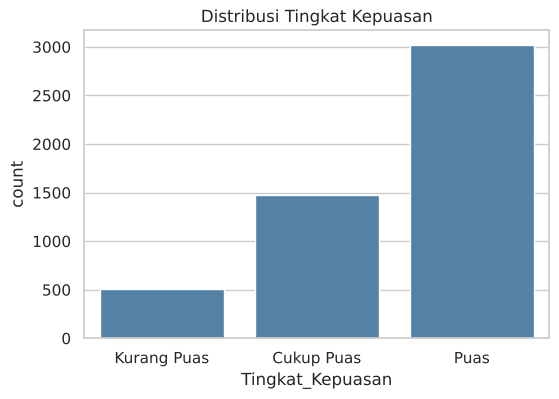

In [6]:
print(df["Tingkat_Kepuasan"].value_counts())
print()
print(df["Tingkat_Kepuasan"].value_counts(normalize=True).round(3))

order = ["Kurang Puas", "Cukup Puas", "Puas"]
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Tingkat_Kepuasan", order=order, color="steelblue")
plt.title("Distribusi Tingkat Kepuasan")
plt.show()

### 3.5 Distribusi Fitur Numerik
Histogram + KDE untuk melihat sebaran tiap fitur.

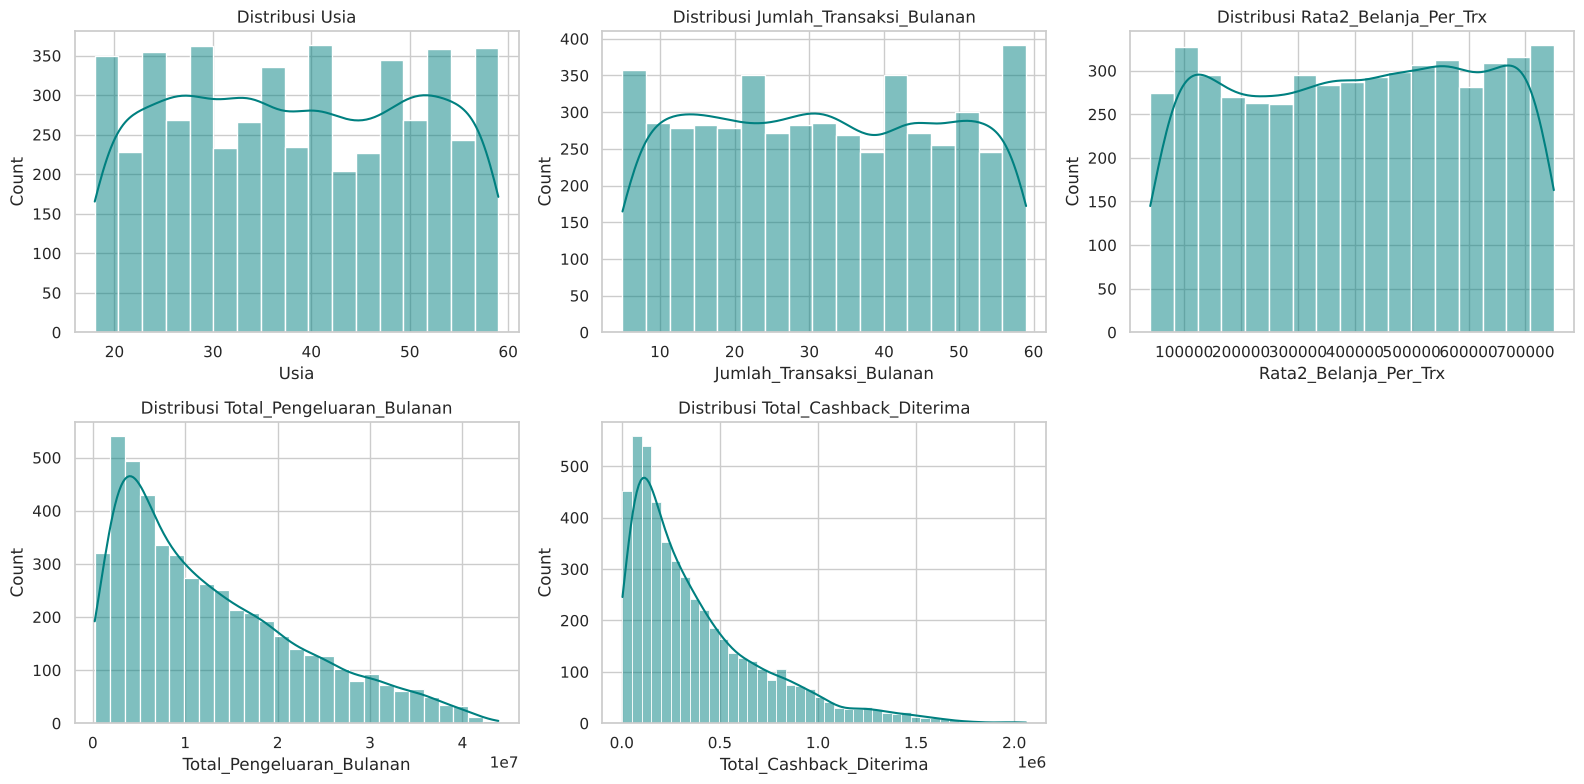

In [7]:
num_cols = ["Usia", "Jumlah_Transaksi_Bulanan", "Rata2_Belanja_Per_Trx",
            "Total_Pengeluaran_Bulanan", "Total_Cashback_Diterima"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="teal")
    ax.set_title(f"Distribusi {col}")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

### 3.6 Fitur Kategorikal
Jumlah pengguna per kota, e-wallet utama, dan jenis kelamin.

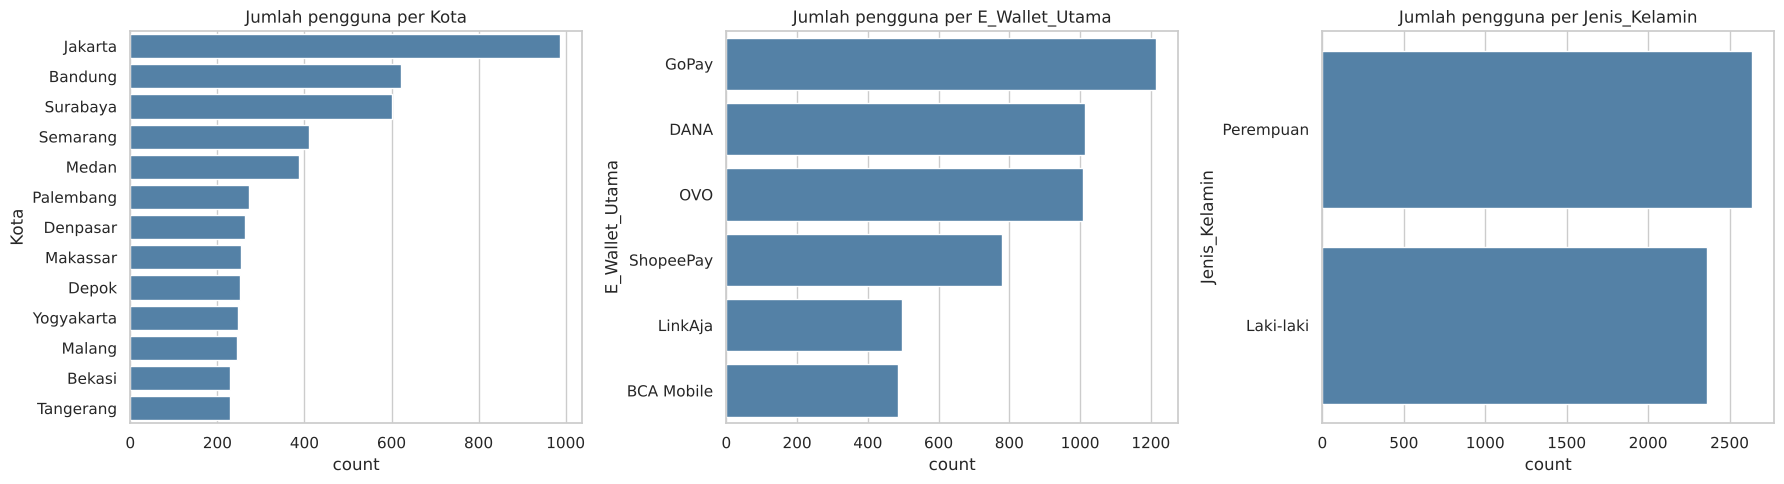

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["Kota", "E_Wallet_Utama", "Jenis_Kelamin"]):
    sns.countplot(data=df, y=col, order=df[col].value_counts().index, color="steelblue", ax=ax)
    ax.set_title(f"Jumlah pengguna per {col}")
plt.tight_layout()
plt.show()

### 3.7 Deteksi Outlier (Boxplot)
Titik di luar "kumis" adalah kandidat outlier. Outlier tidak dihapus karena nilainya masih wajar (misalnya pengguna sangat aktif dengan pengeluaran besar).

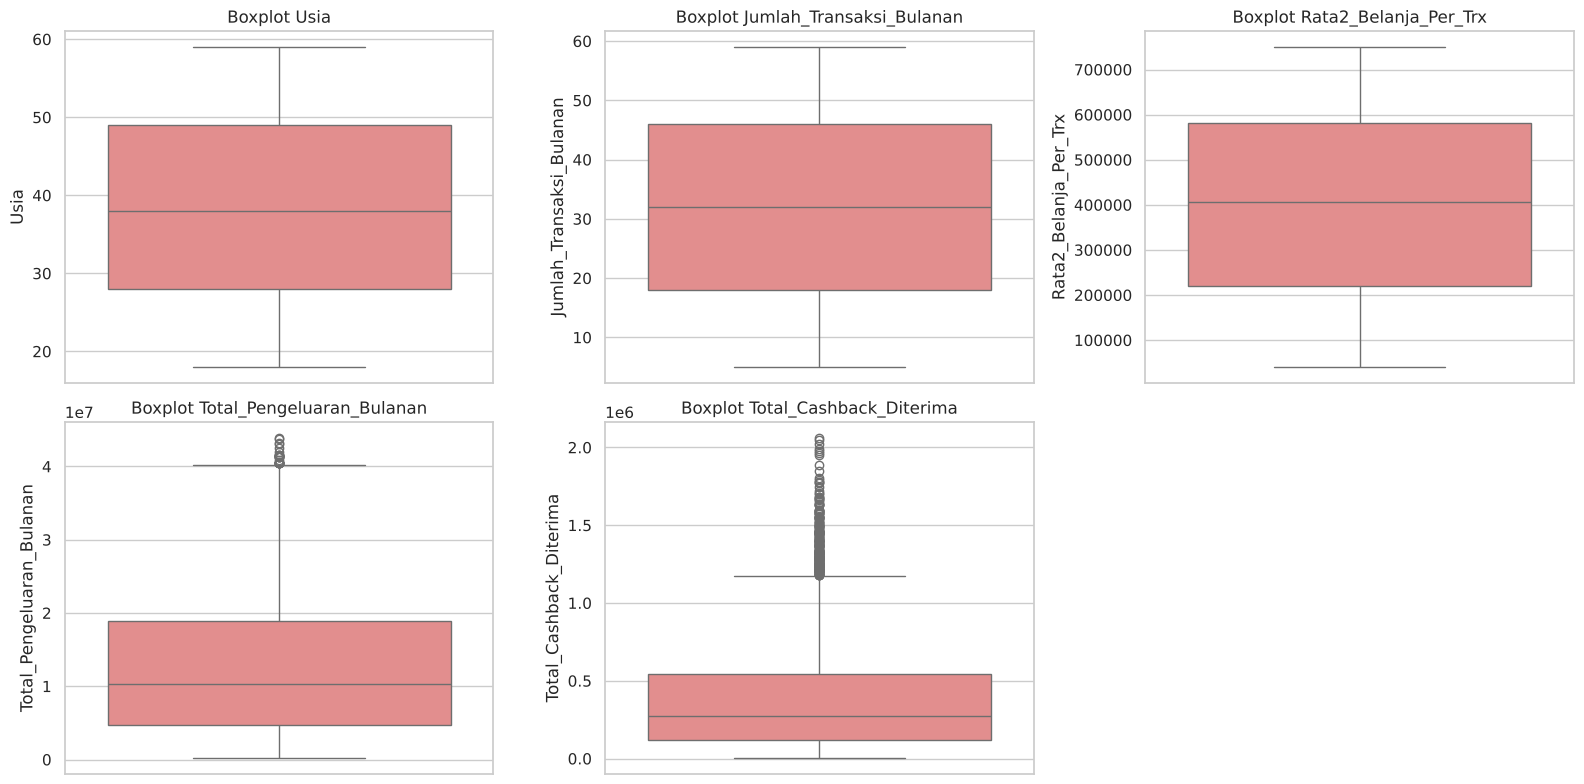

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="lightcoral")
    ax.set_title(f"Boxplot {col}")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

### 3.8 Korelasi Antar Fitur Numerik
Korelasi tinggi menandakan informasi yang tumpang tindih. Wajar bila `Total_Pengeluaran_Bulanan` berkorelasi kuat dengan fitur lain karena nilainya sama dengan **jumlah transaksi × rata-rata belanja** (diverifikasi di bawah).

Selisih maksimum (trx x rata-rata) vs total pengeluaran: 0


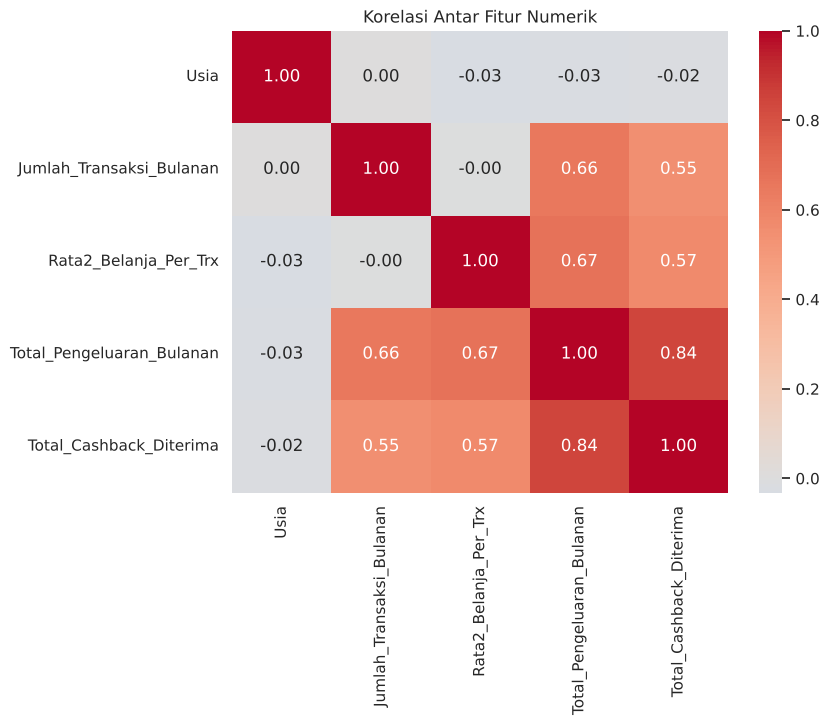

In [10]:
selisih = (df["Jumlah_Transaksi_Bulanan"] * df["Rata2_Belanja_Per_Trx"] - df["Total_Pengeluaran_Bulanan"]).abs().max()
print("Selisih maksimum (trx x rata-rata) vs total pengeluaran:", selisih)

plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi Antar Fitur Numerik")
plt.show()

### 3.9 Hubungan Fitur dengan Tingkat Kepuasan
Apakah ada fitur yang tampak membedakan ketiga kelas kepuasan? Tabel rata-rata dan proporsi kepuasan per e-wallet berikut membantu menjawabnya.

In [11]:
display(df.groupby("Tingkat_Kepuasan")[num_cols].mean().round(1).loc[order])

pd.crosstab(df["E_Wallet_Utama"], df["Tingkat_Kepuasan"], normalize="index")[order].round(3)

,Usia,Jumlah_Transaksi_Bulanan,Rata2_Belanja_Per_Trx,Total_Pengeluaran_Bulanan,Total_Cashback_Diterima
Tingkat_Kepuasan,,,,,
Kurang Puas,39.1,31.0,386507.1,11925352.8,354635.4
Cukup Puas,38.7,32.0,406398.5,13081984.1,391766.3
Puas,38.3,32.0,402731.4,12863922.9,387069.3


Tingkat_Kepuasan,Kurang Puas,Cukup Puas,Puas
E_Wallet_Utama,,,
BCA Mobile,0.101,0.337,0.562
DANA,0.096,0.300,0.604
GoPay,0.098,0.289,0.613
LinkAja,0.095,0.276,0.630
OVO,0.109,0.282,0.609
ShopeePay,0.109,0.299,0.592


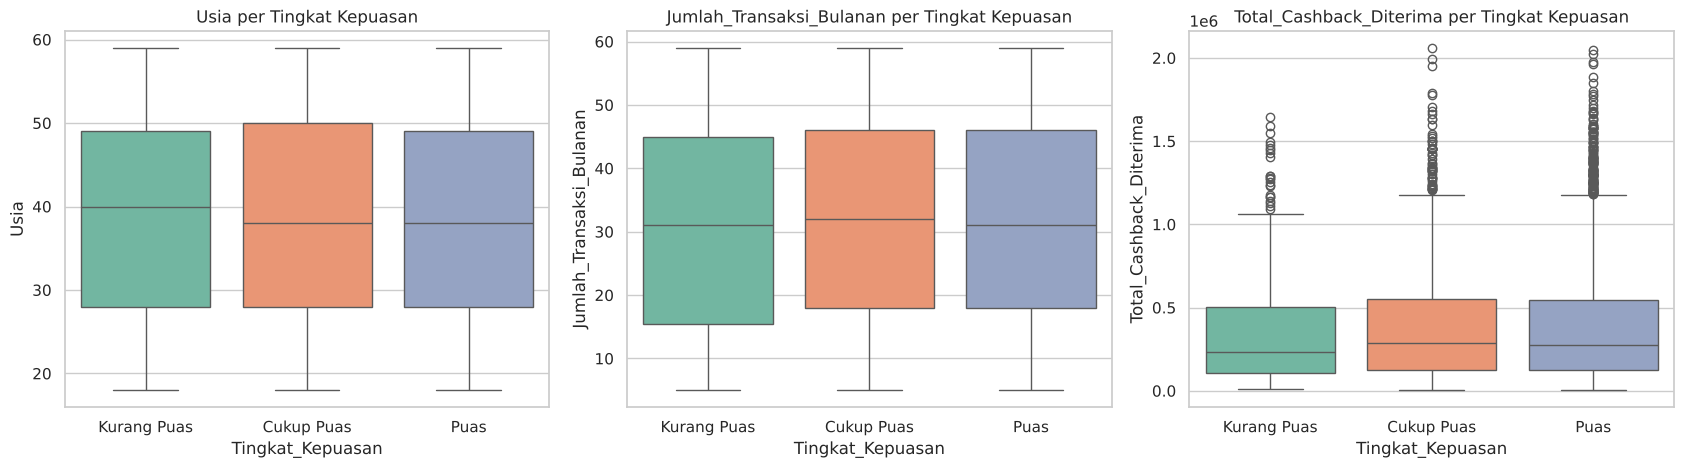

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, ["Usia", "Jumlah_Transaksi_Bulanan", "Total_Cashback_Diterima"]):
    sns.boxplot(data=df, x="Tingkat_Kepuasan", y=col, order=order, ax=ax, palette="Set2")
    ax.set_title(f"{col} per Tingkat Kepuasan")
plt.tight_layout()
plt.show()

**Temuan EDA:** rata-rata fitur dan proporsi kepuasan hampir sama di semua kelompok, sehingga belum ada fitur yang jelas memisahkan kelas. Ini penting untuk menafsirkan hasil model nanti.

## 4. Preprocessing

### 4.1 Pemilihan Fitur dan Rekayasa Fitur
- `User_ID` dan `Nama_Lengkap` **dibuang** karena hanya identitas, bukan sifat pengguna.
- `Total_Pengeluaran_Bulanan` **dibuang** karena redundan (= transaksi × rata-rata belanja).
- Ditambah fitur baru `Rasio_Cashback` = cashback ÷ total pengeluaran (seberapa besar cashback relatif terhadap belanja).

In [13]:
df_model = df.copy()
df_model["Rasio_Cashback"] = df_model["Total_Cashback_Diterima"] / df_model["Total_Pengeluaran_Bulanan"]

target = "Tingkat_Kepuasan"
X = df_model.drop(columns=["User_ID", "Nama_Lengkap", "Total_Pengeluaran_Bulanan", target])
y = df_model[target]

num_features = ["Usia", "Jumlah_Transaksi_Bulanan", "Rata2_Belanja_Per_Trx",
                "Total_Cashback_Diterima", "Rasio_Cashback"]
cat_features = ["Kota", "Jenis_Kelamin", "E_Wallet_Utama"]
print("Fitur numerik    :", num_features)
print("Fitur kategorikal:", cat_features)

Fitur numerik    : ['Usia', 'Jumlah_Transaksi_Bulanan', 'Rata2_Belanja_Per_Trx', 'Total_Cashback_Diterima', 'Rasio_Cashback']
Fitur kategorikal: ['Kota', 'Jenis_Kelamin', 'E_Wallet_Utama']


### 4.2 Split Data Latih dan Uji
Pembagian 80:20 dengan `stratify=y` agar proporsi kelas sama di kedua bagian. Data uji tidak disentuh sampai evaluasi akhir.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print(y_train.value_counts(normalize=True).round(3).to_dict())
print(y_test.value_counts(normalize=True).round(3).to_dict())

Data latih: (4000, 8) | Data uji: (1000, 8)
{'Puas': 0.604, 'Cukup Puas': 0.294, 'Kurang Puas': 0.102}
{'Puas': 0.604, 'Cukup Puas': 0.295, 'Kurang Puas': 0.101}


### 4.3 Pipeline Preprocessing
`StandardScaler` untuk fitur numerik dan `OneHotEncoder` untuk fitur kategorikal, dibungkus dalam `ColumnTransformer`. Karena berada di dalam `Pipeline`, scaler hanya di-*fit* pada data latih (di tiap fold saat cross-validation) sehingga **tidak ada kebocoran data (data leakage)**.

In [15]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

## 5. Pemodelan

### 5.1 Definisi Model
Enam model dibandingkan. **Dummy (majority class)** dipakai sebagai *baseline*: model yang selalu menebak kelas terbanyak. Model sungguhan harus mengalahkan baseline ini agar dianggap benar-benar belajar. Model lain memakai `class_weight="balanced"` karena kelas tidak seimbang.

In [16]:
def buat(clf):
    return Pipeline([("prep", preprocessor), ("clf", clf)])

models = {
    "Baseline (Dummy)":     buat(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression":  buat(LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    "KNN":                  buat(KNeighborsClassifier(n_neighbors=15)),
    "Decision Tree":        buat(DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE)),
    "Random Forest":        buat(RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting":    buat(GradientBoostingClassifier(random_state=RANDOM_STATE)),
}

### 5.2 Pelatihan dan Perbandingan Model
Setiap model dievaluasi dengan **Stratified 5-Fold Cross-Validation** pada data latih (accuracy dan macro-F1), lalu dilatih ulang dan diuji pada data uji. Macro-F1 memberi bobot sama pada tiap kelas sehingga lebih jujur daripada accuracy untuk data tidak seimbang.

In [17]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
hasil = []

for nama, model in models.items():
    cv_acc = cross_val_score(model, X_train, y_train, cv=skf, scoring="accuracy")
    cv_f1 = cross_val_score(model, X_train, y_train, cv=skf, scoring="f1_macro")
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    hasil.append({
        "Model": nama,
        "CV Accuracy": cv_acc.mean(),
        "CV Macro-F1": cv_f1.mean(),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Macro-F1": f1_score(y_test, pred, average="macro"),
    })

hasil_df = pd.DataFrame(hasil).sort_values("CV Macro-F1", ascending=False).reset_index(drop=True)
hasil_df.round(4)

,Model,CV Accuracy,CV Macro-F1,Test Accuracy,Test Macro-F1
0,Random Forest,0.4990,0.3297,0.508,0.3220
1,KNN,0.5650,0.2948,0.571,0.2971
2,Logistic Regression,0.3192,0.2914,0.346,0.3099
3,Gradient Boosting,0.5880,0.2652,0.594,0.2643
4,Decision Tree,0.2902,0.2634,0.237,0.2259
5,Baseline (Dummy),0.6040,0.2510,0.604,0.2510


### 5.3 Visualisasi Perbandingan Model

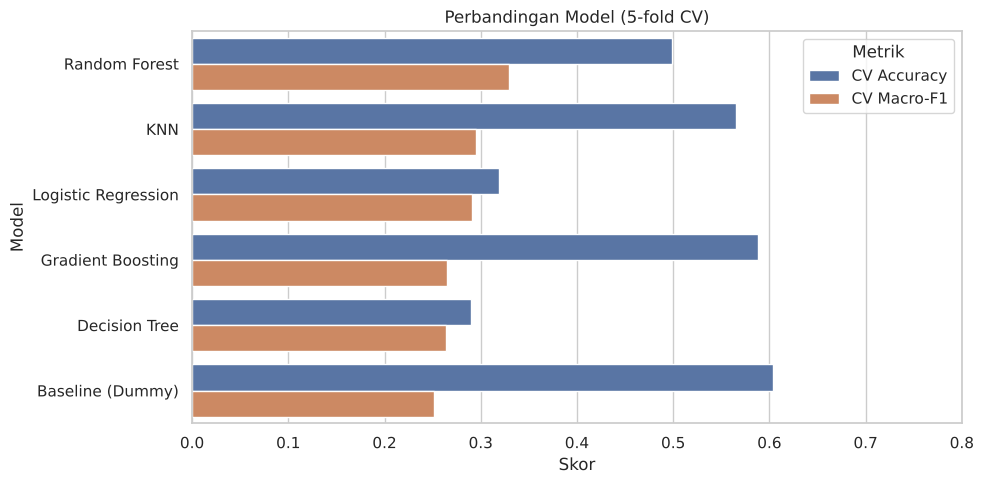

In [18]:
hasil_long = hasil_df.melt(id_vars="Model", value_vars=["CV Accuracy", "CV Macro-F1"],
                           var_name="Metrik", value_name="Skor")
plt.figure(figsize=(10, 5))
sns.barplot(data=hasil_long, x="Skor", y="Model", hue="Metrik")
plt.title("Perbandingan Model (5-fold CV)")
plt.xlim(0, 0.8)
plt.tight_layout()
plt.show()

**Catatan:** accuracy baseline sekitar 60% (proporsi kelas *Puas*). Model yang tidak mengalahkan angka itu belum menemukan pola yang berguna. Macro-F1 baseline sangat rendah (~0.25) karena tidak pernah menebak dua kelas lainnya.

## 6. Hyperparameter Tuning
Dipilih **Random Forest** untuk di-tuning dengan `GridSearchCV` (skor: macro-F1) karena banyak hyperparameter dan umumnya tangguh. `min_samples_leaf` dan `max_depth` yang lebih besar/dangkal membantu mengurangi overfitting.

In [19]:
param_grid = {
    "clf__n_estimators": [200, 400],
    "clf__max_depth": [None, 5, 10],
    "clf__min_samples_leaf": [1, 5, 20],
}

grid = GridSearchCV(
    buat(RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)),
    param_grid, cv=skf, scoring="f1_macro", n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Parameter terbaik :", grid.best_params_)
print("CV Macro-F1 terbaik:", round(grid.best_score_, 4))
model_final = grid.best_estimator_

Parameter terbaik : {'clf__max_depth': None, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 400}
CV Macro-F1 terbaik: 0.3321


## 7. Evaluasi Model Akhir
### 7.1 Accuracy, Macro-F1, dan Classification Report
Model akhir diuji **sekali** pada data uji. `precision` = ketepatan prediksi, `recall` = cakupan data asli, `f1-score` = rangkuman keduanya.

In [20]:
y_pred = model_final.predict(X_test)
print("Accuracy data uji :", round(accuracy_score(y_test, y_pred), 4))
print("Macro-F1 data uji :", round(f1_score(y_test, y_pred, average="macro"), 4))
base_acc = y_test.value_counts(normalize=True).max()
print("Accuracy baseline :", round(base_acc, 4), "(selalu menebak 'Puas')")
print()
print(classification_report(y_test, y_pred, labels=order))

Accuracy data uji : 0.449
Macro-F1 data uji : 0.3446
Accuracy baseline : 0.604 (selalu menebak 'Puas')

              precision    recall  f1-score   support

 Kurang Puas       0.10      0.15      0.12       101
  Cukup Puas       0.32      0.34      0.33       295
        Puas       0.62      0.55      0.58       604

    accuracy                           0.45      1000
   macro avg       0.35      0.35      0.34      1000
weighted avg       0.48      0.45      0.46      1000



### 7.2 Confusion Matrix
Baris = kelas sebenarnya, kolom = kelas prediksi. Diagonal adalah prediksi yang benar.

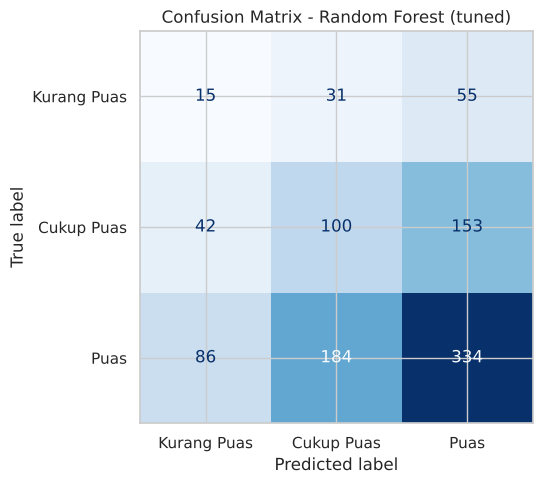

In [21]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=order, cmap="Blues", ax=ax, colorbar=False)
plt.title("Confusion Matrix - Random Forest (tuned)")
plt.tight_layout()
plt.show()

### 7.3 Feature Importance
Seberapa besar tiap fitur berkontribusi pada keputusan Random Forest (fitur kategorikal sudah di-one-hot, sehingga tampil per kategori).

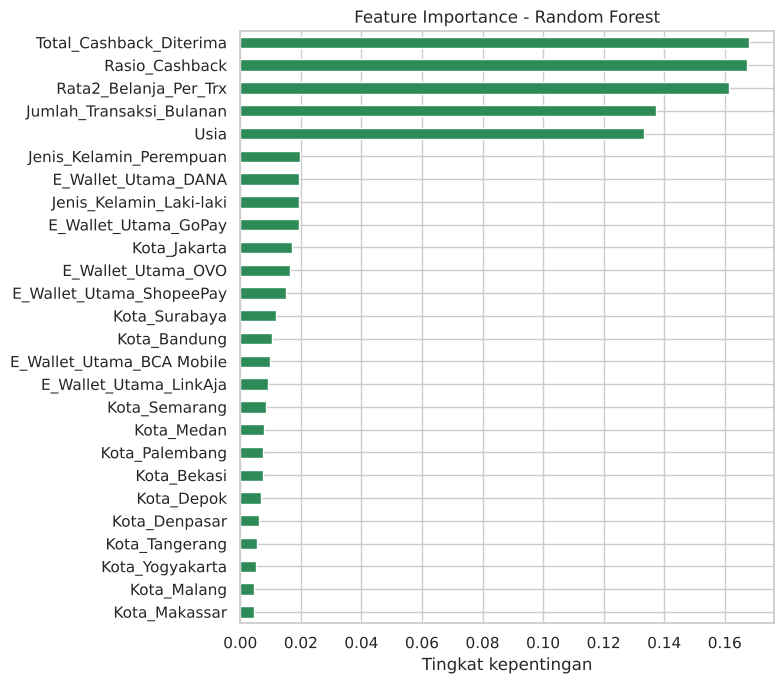

In [22]:
nama_fitur = model_final.named_steps["prep"].get_feature_names_out()
nama_fitur = [n.split("__", 1)[1] for n in nama_fitur]
imp = pd.Series(model_final.named_steps["clf"].feature_importances_, index=nama_fitur).sort_values()

plt.figure(figsize=(8, 7))
imp.plot(kind="barh", color="seagreen")
plt.title("Feature Importance - Random Forest")
plt.xlabel("Tingkat kepentingan")
plt.tight_layout()
plt.show()

## 8. Prediksi Data Baru
Contoh penggunaan model: isi data seorang pengguna, model memberi prediksi kepuasan beserta probabilitasnya. **Ubah nilai pada dictionary untuk mencoba kondisi lain.**

In [23]:
data_baru = pd.DataFrame([{
    "Kota": "Jakarta", "Usia": 30, "Jenis_Kelamin": "Perempuan",
    "E_Wallet_Utama": "GoPay", "Jumlah_Transaksi_Bulanan": 25,
    "Rata2_Belanja_Per_Trx": 300000, "Total_Cashback_Diterima": 200000,
}])
data_baru["Rasio_Cashback"] = data_baru["Total_Cashback_Diterima"] / (
    data_baru["Jumlah_Transaksi_Bulanan"] * data_baru["Rata2_Belanja_Per_Trx"])
data_baru = data_baru[X.columns]

print("Prediksi kepuasan:", model_final.predict(data_baru)[0])
proba = pd.Series(model_final.predict_proba(data_baru)[0], index=model_final.classes_)
print(proba.round(3).sort_values(ascending=False))

Prediksi kepuasan: Kurang Puas
Kurang Puas    0.386
Puas           0.309
Cukup Puas     0.304
dtype: float64


## 9. Simpan Model
Model (sudah termasuk preprocessing) disimpan ke file agar bisa dipakai lagi tanpa melatih ulang: `joblib.load("model_kepuasan_rf.pkl")`.

In [24]:
joblib.dump(model_final, "model_kepuasan_rf.pkl")
joblib.dump(list(X.columns), "kolom_fitur.pkl")
print("Model dan daftar kolom fitur berhasil disimpan.")

Model dan daftar kolom fitur berhasil disimpan.


## 10. Kesimpulan

- Dataset berisi **5.000 pengguna**, 11 kolom, **tanpa missing value maupun duplikat**. Target `Tingkat_Kepuasan` tidak seimbang (*Puas* ≈ 60%, *Cukup Puas* ≈ 30%, *Kurang Puas* ≈ 10%).
- `Total_Pengeluaran_Bulanan` = transaksi × rata-rata belanja (redundan), sehingga dibuang; ID dan nama juga dibuang.
- Enam model dibandingkan dengan 5-fold CV, dan Random Forest di-tuning dengan GridSearchCV (skor macro-F1).
- **Temuan utama:** model terbaik (Random Forest) hanya mencapai **macro-F1 ≈ 0,34** (baseline 0,25) dengan **accuracy ≈ 45%**, jauh di bawah accuracy baseline 60% yang selalu menebak "Puas". Accuracy turun karena `class_weight="balanced"` memaksa model memprediksi kelas minoritas (yang sulit ditebak), sehingga macro-F1 sedikit naik tetapi kelas *Kurang Puas* tetap hampir tidak terdeteksi (F1 ≈ 0,12).
- Artinya, **fitur yang tersedia (profil dan transaksi) hampir tidak membawa informasi tentang tingkat kepuasan** pada dataset ini, konsisten dengan EDA yang menunjukkan rata-rata fitur yang hampir sama antar kelas.
- Pola seperti ini lazim pada data sintetis/acak; hasil dilaporkan apa adanya, bukan dipaksakan naik. Untuk memperbaiki dibutuhkan fitur yang lebih relevan (misalnya keluhan, waktu respons, tingkat kegagalan transaksi, atau skor ulasan).